In [1]:
from sqlalchemy import create_engine, text
from dotenv import load_dotenv
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error, r2_score

In [4]:
# 1. датасет Medical Insurance с Kaggle
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


где bmi - индекс массы тела

### Возмем в качестве целевой переменной charges (стоимость страховки)

In [8]:
# Преобразуем все в числовой формат с помощью функции get_dummies

df_encoded = pd.get_dummies(df, columns = ['sex', 'smoker'], drop_first=True)
df_encoded = pd.get_dummies(df_encoded, columns = ['region'], drop_first=False)

df_encoded.head()

,age,bmi,children,charges,target,sex_male,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,False,True,False,False,False,True
1,18,33.770,1,1725.55230,0,True,False,False,False,True,False
2,28,33.000,3,4449.46200,0,True,False,False,False,True,False
3,33,22.705,0,21984.47061,1,True,False,False,True,False,False
4,32,28.880,0,3866.85520,0,True,False,False,True,False,False


### Постройте точечные диаграммы (scatterplots) для таргета и каждой фичи, опишите форму взаимосвязи между переменными

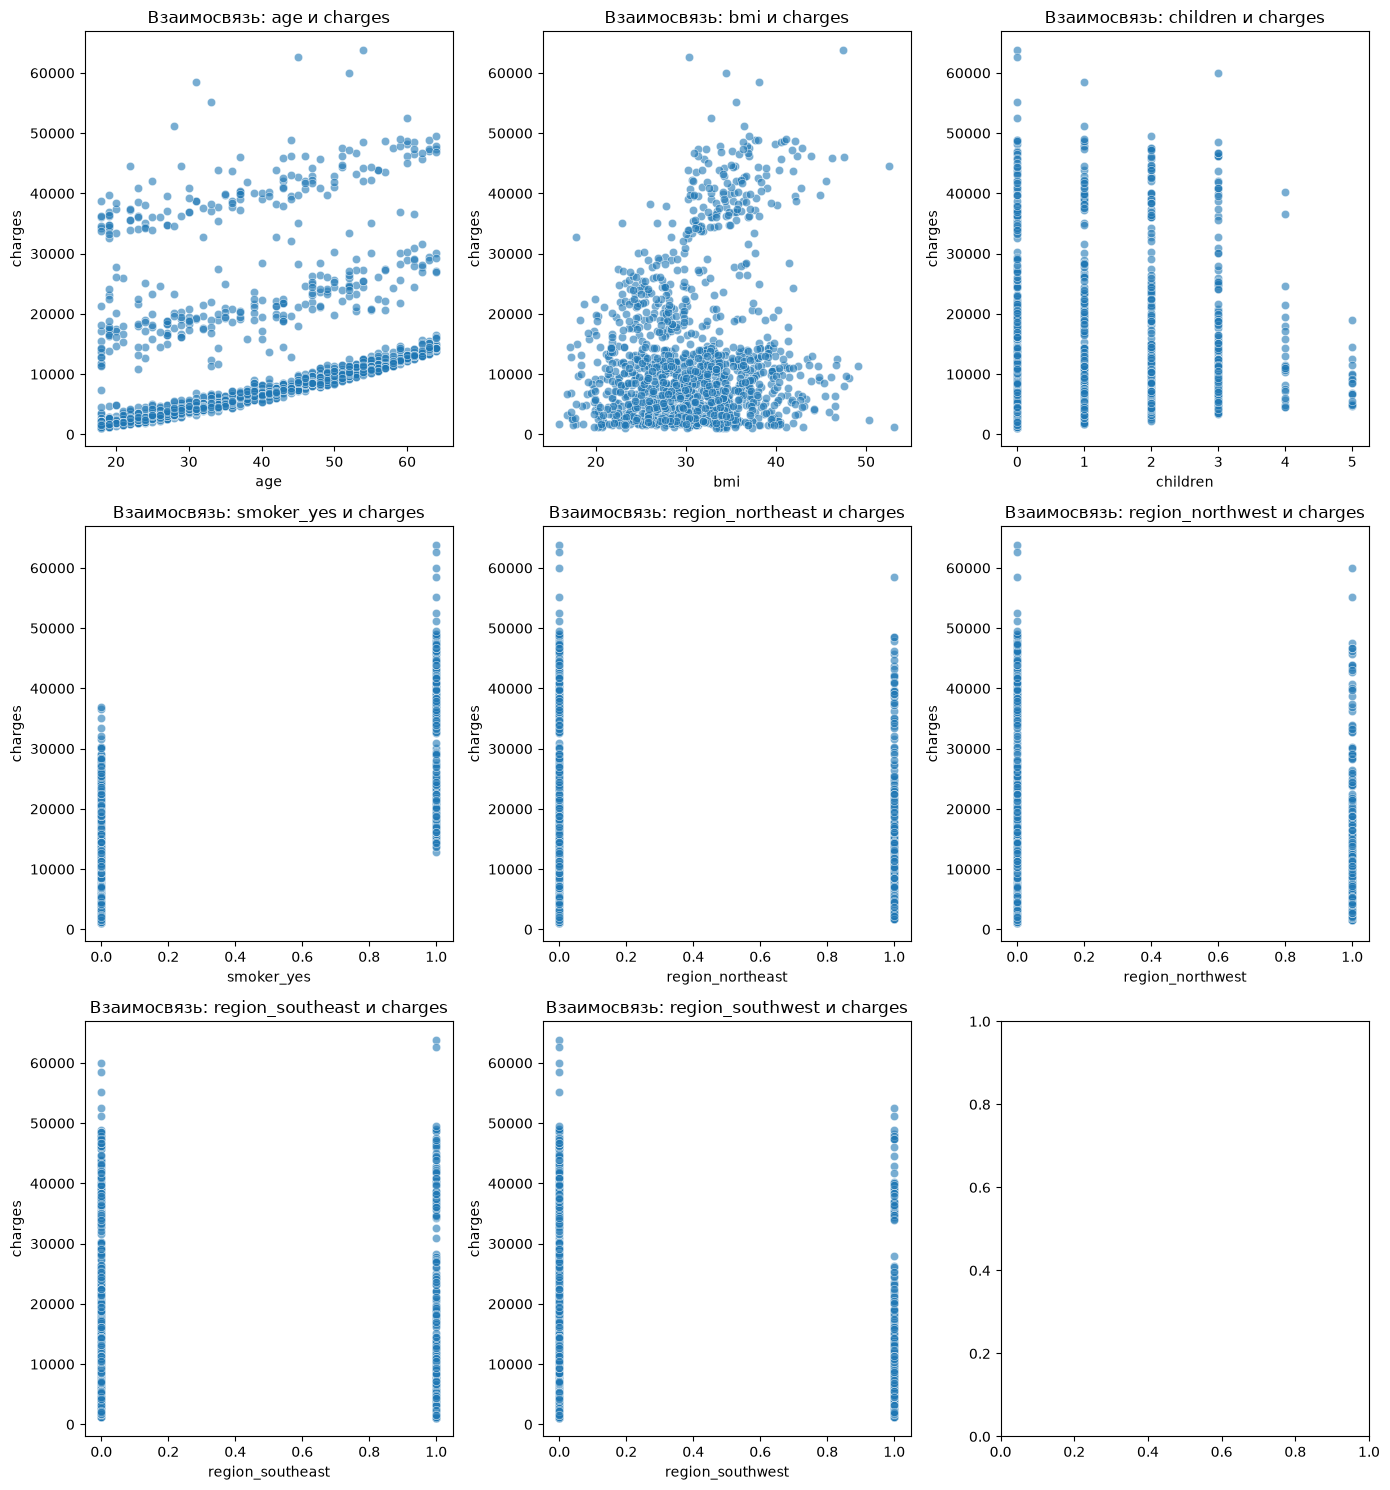

In [9]:
features_to_plot = ['age', 'bmi', 'children', 'smoker_yes', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']
target = 'charges'

fig, axes = plt.subplots(3, 3, figsize=(14, 15))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.scatterplot(data=df_encoded, x=feature, y=target, alpha=0.6, ax=axes[i])
    axes[i].set_title(f'Взаимосвязь: {feature} и {target}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel(target)

plt.tight_layout()
plt.show()

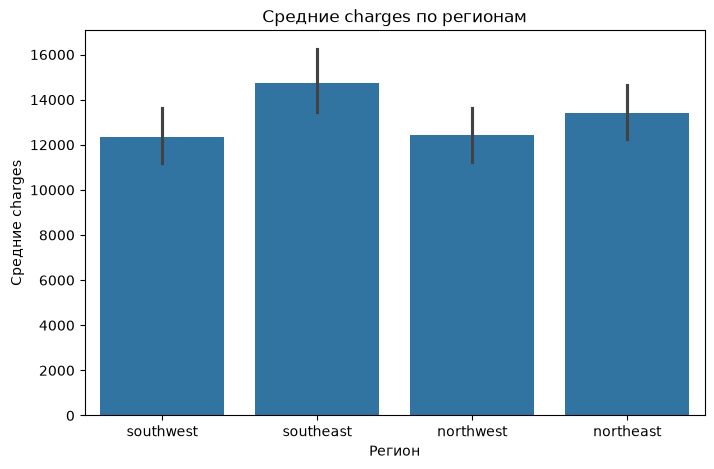

In [23]:
#Посмотрим отличаются ли регионы между собой

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='region', y='charges',
            estimator='mean', errorbar='ci')
plt.title('Средние charges по регионам')
plt.xlabel('Регион')
plt.ylabel('Средние charges')
plt.show()

Связи страховки с регионом не наблюдается.

Видна связь размера страховки с возрастом, курением, количеством детей.

Совсем небольшая связь наблюдается с bmi

### Разделите датасет на обучающую и тестовую выборки

In [25]:
def split_train_test(df, features_col, target_col, to_scale = False):
    X = df[features_col]
    y = df[target_col]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, random_state = 42)
    if to_scale:
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
    
    return X_train, X_test, y_train, y_test

In [26]:
target_col = ['charges']
features_col = ['age', 'bmi', 'children', 'smoker_yes']
X_train, X_test, y_train, y_test = split_train_test(df_encoded, features_col, target_col)

### Обучите модель линейной регрессии на разных наборах переменных и для разных спецификаций модели на обучающей выборке

In [ ]:
def train_model(X_train, y_train):
    model = LinearRegression()
    model.fit(X_train, y_train)
    return model

def get_predictions(model, X_test):
    return model.predict(X_test)

def visualize_prediction(y_true, y_pred):
    fig, ax = plt.subplots(1,1, figsize = (5,5))
    sns.scatterplot(x = y_true.values.ravel(), y = y_pred.ravel(), ax = ax)
    sns.lineplot(x = y_true.values.ravel(), y = y_true.values.ravel(), linestyle = '--', color = 'lightblue', ax = ax)
    ax.set_title("Истинные и предсказанные значения y")
    ax.set_xlabel('true y')
    ax.set_ylabel('pred y')
    plt.show()

def show_metrics(y_true, y_pred):
    print('Среднее значение Y: ', np.mean(y_true))
    print('Среднеквадратическое отклонение Y: ', np.std(y_test, axis = 0).values[0])
    print('MSE: ', mean_squared_error(y_true, y_pred)),
    print('RMSE: ', root_mean_squared_error(y_true, y_pred))
    print('MAE: ', mean_absolute_error(y_true, y_pred))
    print('MAPE: ', mean_absolute_percentage_error(y_true, y_pred))
    print('R2: ', r2_score(y_true, y_pred))

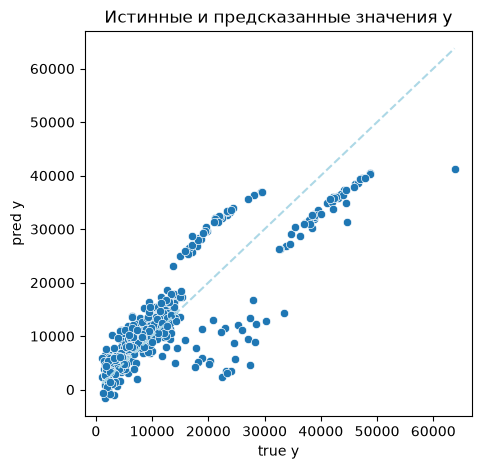

Среднее значение Y:  13048.923798052034
Среднеквадратическое отклонение Y:  12105.563015065558
MSE:  35299792.100293264
RMSE:  5941.362815069727
MAE:  4210.867850540483
MAPE:  0.4411509492369087
R2:  0.7591192126340146


In [35]:
model = train_model(X_train, y_train.values.ravel())
y_pred = get_predictions(model, X_test)
visualize_prediction(y_test, y_pred)
show_metrics(y_test, y_pred)

## Чтобы упростить задачу визуализации и сравнения создадим класс для обучения моделей с разными параметрами

In [55]:
class ML_insurance:
    def __init__(self, df, features_col, show = False,
                 model_kind='linear', to_scale=False, random_state=42,
                 test_size=0.33, target_col='charges', proba = False):
        self.df = df
        self.features_col = features_col
        self.model_kind = model_kind
        self.target_col = target_col
        self.test_size = test_size
        self.random_state = random_state
        self.proba = proba

        # if self.model_kind in ('lasso', 'ridge'):
        #     to_scale = True

        # сразу готовим данные и обучаем
        self.split_train_test(to_scale=to_scale)
        self.model = self.train_model()
        # смотрим результат на тестовой выборке
        self.y_pred = self.model.predict(self.X_test)

        # считаем качественные харктеристики модели
        self.set_metrics(self.y_test, self.y_pred)

        # визуализируем
        if show is True:
            self.visualize_prediction(self.y_test, self.y_pred)
            self.show_metrics(self.y_test, self.y_pred)

    def split_train_test(self, to_scale=False):
        X = self.df[self.features_col]
        y = self.df[self.target_col]
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=self.test_size, random_state=self.random_state
        )
        if to_scale:
            self.scaler = StandardScaler()
            self.X_train = self.scaler.fit_transform(self.X_train)
            self.X_test = self.scaler.transform(self.X_test)

    def train_model(self):
        model = LinearRegression()
        model.fit(self.X_train, self.y_train)
        return model

    # def get_predictions(self):
    #     return self.model.predict(self.X_test)


    def visualize_prediction(self, y_true, y_pred):
        fig, ax = plt.subplots(1,1, figsize = (5,5))
        sns.scatterplot(x = y_true.values.ravel(), y = y_pred.ravel(), ax = ax)
        sns.lineplot(x = y_true.values.ravel(), y = y_true.values.ravel(), linestyle = '--', color = 'lightblue', ax = ax)
        ax.set_title(f"значения y ({self.model_kind}, random={self.random_state}, {self.features_col})")
        ax.set_xlabel('true y')
        ax.set_ylabel('pred y')
        plt.show()
  
    def set_metrics(self, y_true, y_pred):
        self.mean_Y = np.mean(y_true)
        self.std = np.std(y_true, axis = 0)
        self.mse = mean_squared_error(y_true, y_pred)
        self.rmse = root_mean_squared_error(y_true, y_pred)
        self.mae = mean_absolute_error(y_true, y_pred)
        self.mape = mean_absolute_percentage_error(y_true, y_pred)
        self.r2 = r2_score(y_true, y_pred)

    def show_metrics(self, y_true, y_pred):
        print('Среднее значение Y: ', self.mean_Y)
        print('Среднеквадратическое отклонение Y: ', self.std)
        print('MSE: ', self.mse)
        print('RMSE: ', self.rmse)
        print('MAE: ', self.mae)
        print('MAPE: ', self.mape)
        print('R2: ', self.r2)

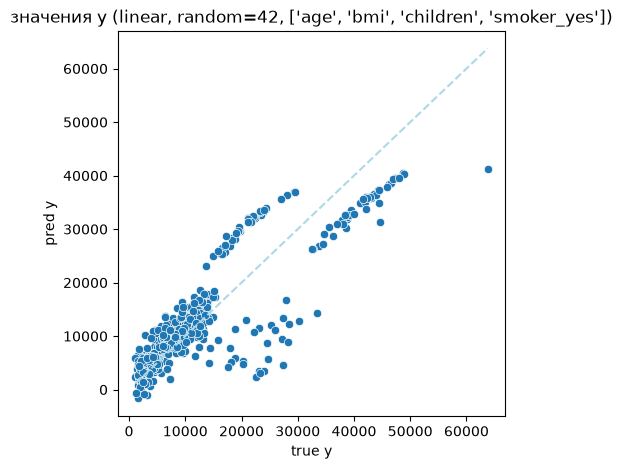

Среднее значение Y:  13048.923798052034
Среднеквадратическое отклонение Y:  12105.563015065558
MSE:  35299792.100293264
RMSE:  5941.362815069727
MAE:  4210.867850540483
MAPE:  0.4411509492369087
R2:  0.7591192126340146


In [53]:
# Посмотрим работает ли
test=ML_insurance(df_encoded, features_col = ['age', 'bmi', 'children', 'smoker_yes'], show=True)

функция для визуального сравнения показателей моделей (LLM)

In [92]:
def compare_models(models_dict, figsize=(14, 10)):
    """
    Строит графики сравнения метрик для нескольких моделей ML_insurance (регрессия).

    Parameters:
    -----------
    models_dict : dict
        Словарь вида {'имя_модели': объект_ML_insurance, ...}
    figsize : tuple
        Размер фигуры (ширина, высота)
    """
    all_metrics = ['MSE', 'RMSE', 'MAE', 'MAPE', 'R2']
    names = list(models_dict.keys())
    n_models = len(names)

    # Собираем значения метрик в матрицу [n_models x n_metrics]
    values_all = np.array([
        [m.mse, m.rmse, m.mae, m.mape, m.r2]
        for m in models_dict.values()
    ])

    fig, axes = plt.subplots(2, 2, figsize=figsize)

    # --- График 1: R2 (выше — лучше) ---
    ax = axes[0, 0]
    r2_vals = values_all[:, 4]
    bars = ax.bar(names, r2_vals, color='steelblue', alpha=0.85)
    for bar, val in zip(bars, r2_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_ylabel('R²')
    ax.set_title('Коэффициент детерминации R² (выше — лучше)', fontsize=12)
    ax.grid(axis='y', alpha=0.3)

    # --- График 2: MAPE (ниже — лучше) ---
    ax = axes[0, 1]
    mape_vals = values_all[:, 3]
    bars = ax.bar(names, mape_vals, color='orange', alpha=0.85)
    for bar, val in zip(bars, mape_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('MAPE')
    ax.set_title('MAPE (ниже — лучше)', fontsize=12)
    ax.grid(axis='y', alpha=0.3)

    # --- График 3: MSE / RMSE / MAE (ниже — лучше) ---
    ax = axes[1, 0]
    err_names = ['MSE', 'RMSE', 'MAE']
    x = np.arange(len(err_names))
    width = 0.8 / n_models

    for i, (name, model) in enumerate(models_dict.items()):
        vals = [model.mse, model.rmse, model.mae]
        offset = (i - (n_models - 1) / 2) * width
        bars = ax.bar(x + offset, vals, width, label=name, alpha=0.85)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                    f'{val:.2f}', ha='center', va='bottom',
                    fontsize=8, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(err_names)
    ax.set_ylabel('Значение ошибки')
    ax.set_title('Ошибки MSE / RMSE / MAE (ниже — лучше)', fontsize=12)
    ax.legend(loc='upper right')
    ax.grid(axis='y', alpha=0.3)

    # --- График 4: heatmap всех метрик ---
    ax = axes[1, 1]
    sns.heatmap(values_all, annot=True, fmt='.3f', cmap='YlOrRd',
                xticklabels=all_metrics, yticklabels=names,
                ax=ax, cbar_kws={'label': 'Value'})
    ax.set_title('Тепловая карта метрик', fontsize=12)
    ax.set_ylabel('Модель')

    plt.tight_layout()
    plt.show()

Создадим 4 класс для сравнения

In [102]:
ml_age=ML_insurance(df_encoded, target_col = "target" , features_col = ["age"])
ml_children=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "children"])
bmi=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "bmi"])
ml_smoke=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "smoker_yes"])
ml_region=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "region_southeast"])
ml_all=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "smoker_yes", 'children', 'bmi','region_southeast'])
ml_best7=ML_insurance(df_encoded, target_col = "target" , features_col = ["age", "smoker_yes", 'children'])

models = {
    'age': ml_age,
    'age+children': ml_children,
    'age+bmi': bmi,
    'age+smoke': ml_smoke,
    'age+region': ml_region,
    'age+all': ml_all,
    'age+s+ch': ml_best7,

}

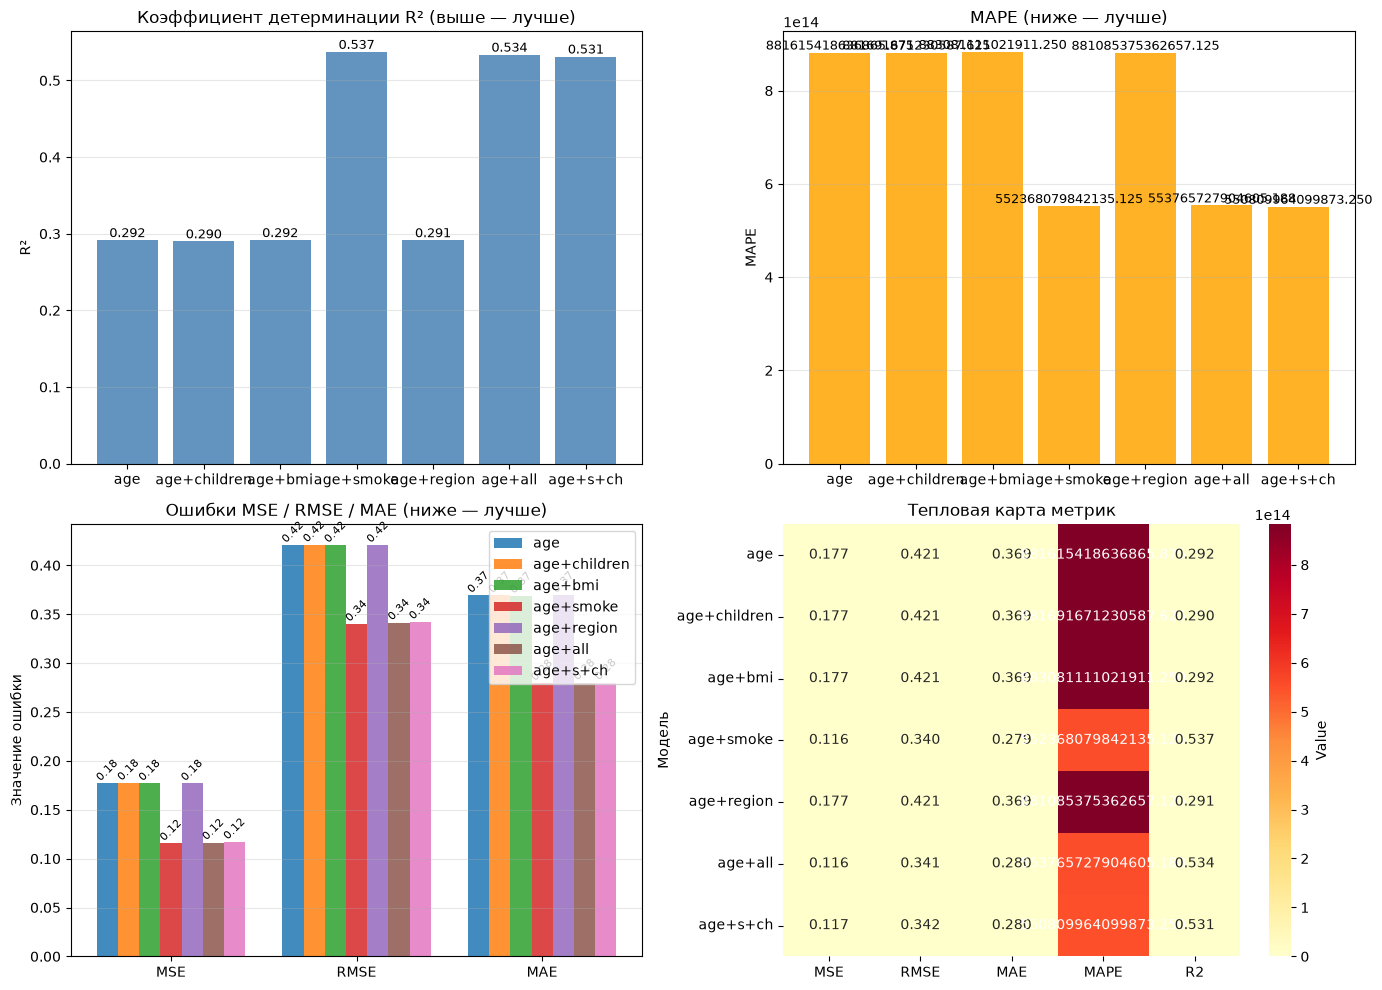

In [103]:
compare_models(models)

По всем метрикам лидером является линейная модель с набором ["age", "smoker_yes"]

### Протестируем на разных спецификациях

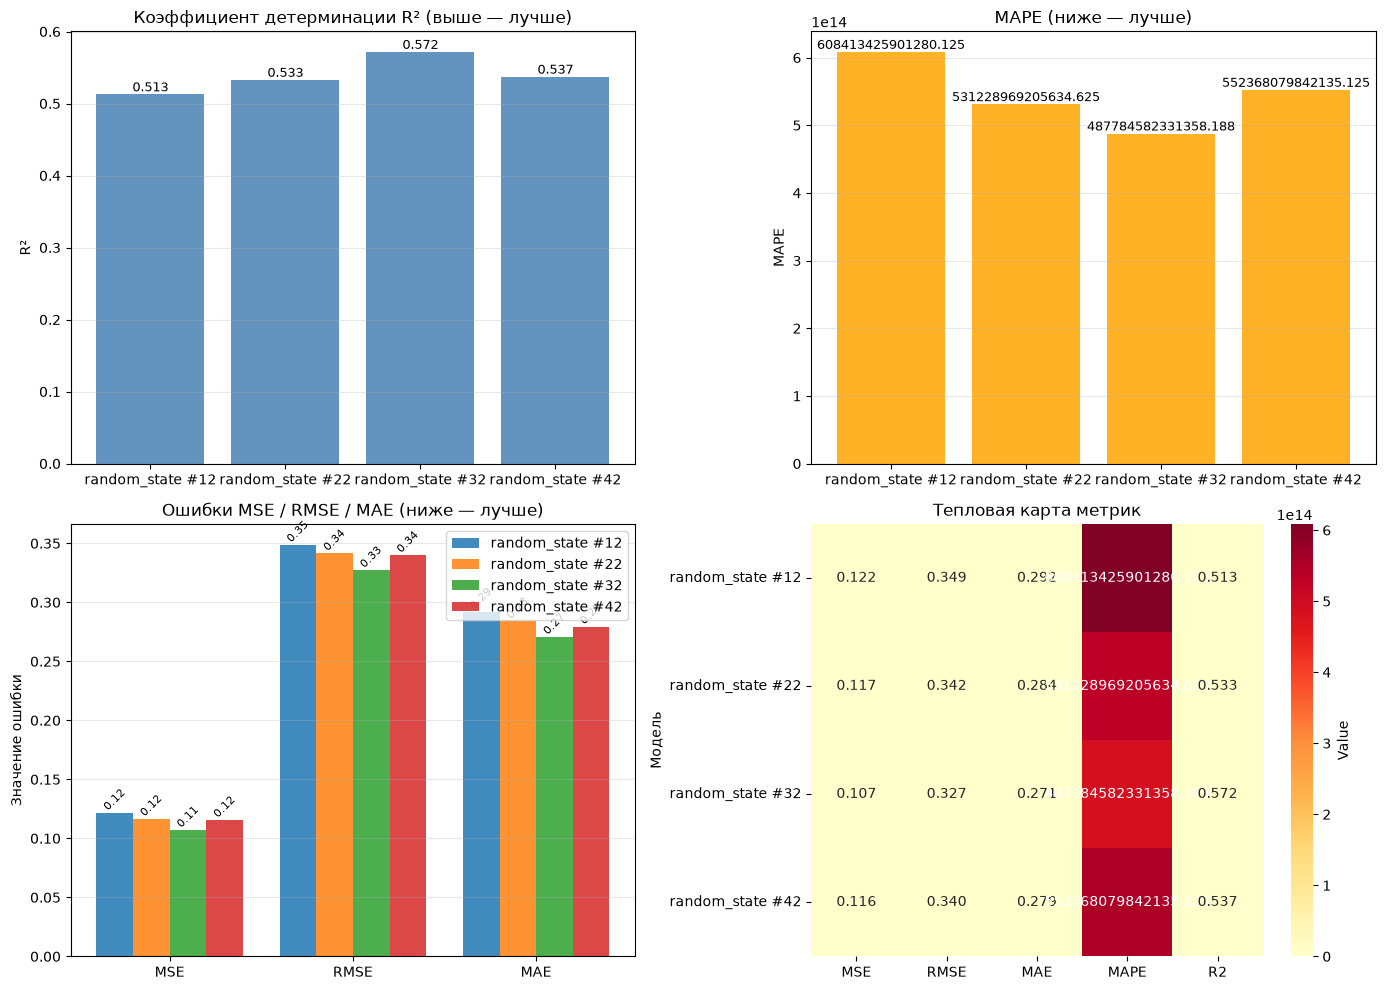

In [104]:
models = {
    f"random_state #{random_state}": ML_insurance(
        df_encoded,
        target_col="target",
        features_col=["age", "smoker_yes"],
        random_state=random_state
    )
    for random_state in [12, 22, 32, 42]
}

compare_models(models)

Плюс-миниус все стабильно, на разных рандомах предсказания не ломаются